# Passaggio 2: dati di prezzo intraday delle coppie scelte

**Obiettivo.** Dal dataset a 1 minuto (`data/processed/intraday_1m_all.parquet`) costruire, per ognuna delle 10 coppie del Passaggio 1, un **file pulito** con i due titoli allineati sugli stessi minuti. Sarà il punto di partenza per il segnale (Passaggio 4) e per la simulazione (Passaggio 6).

**Cosa fa il notebook**

| Parte | Cosa fa | Perché |
|---|---|---|
| 1-2 | Parametri e caricamento dei 20 titoli | si lavora solo sui titoli che servono |
| 3 | Controllo dei prezzi non aggiustati | gli split non devono sembrare crolli |
| 4 | Qualità dei dati grezzi | barre per giorno, giorni mancanti, giorni a orario ridotto |
| 5 | Funzione di pulizia: allineamento e riempimento | il cuore del passaggio |
| 6 | Pulizia delle 10 coppie e controlli | quante barre riempite o scartate |
| 7 | Barre da 5, 15 e 60 minuti | per scegliere la frequenza dopo (decisione 1 del programma) |
| 8 | Un grafico per coppia | controllo a occhio |
| 9 | Salvataggio e riepilogo | file per le fasi successive |

**Regole del programma applicate** (Passaggio 2 di `docs/Programma.md`):
- un solo fuso orario, l'ora di New York (i dati sono già convertiti da `src/data.py`), e solo la **seduta regolare, 09:30-15:59** (390 barre da 1 minuto);
- i due titoli di ogni coppia sono **allineati sullo stesso orario**;
- le barre mancanti si riempiono **solo copiando in avanti il prezzo precedente, mai con prezzi futuri** (Lezione 5): usare prezzi futuri sarebbe lookahead bias;
- i prezzi devono essere **aggiustati per split e dividendi**;
- controlli: numero di barre per giorno, giorni a orario ridotto, un grafico per coppia.

**Cosa NON si tocca:** la lista delle coppie, i dati del periodo di selezione giornaliero e le soglie del Passaggio 1.

## 1. Parametri

In [1]:
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from pathlib import Path

SELECTED = "../data/processed/selected_pairs.csv"            # lista delle 10 coppie (Passaggio 1)
INTRADAY = "../data/processed/intraday_1m_all.parquet"        # barre da 1 minuto, orari di New York
DAILY    = "../data/processed/daily_all.parquet"
OUT_DIR  = Path("../data/processed/pairs_intraday")           # file puliti (cartella ignorata da git)

SESSION_OPEN_MIN = 9 * 60 + 30      # apertura 09:30, in minuti dalla mezzanotte
N_MINUTES = 390                     # barre da 1 minuto nella seduta regolare: 09:30-15:59
FREQUENCIES = [1, 5, 15, 60]        # minuti per barra
# [ECO] Il programma dice di tenere il minuto e creare le altre con resample: la frequenza giusta si sceglie
#   confrontando i risultati (decisione 1), quindi si salvano tutte.

SPLIT_GAP = 0.15                    # gap tra chiusura di ieri e apertura di oggi oltre il 15%: sospetto split
CLOSE_VS_DAILY_TOL = 0.05           # chiusura intraday contro PX_LAST giornaliero oltre il 5%: sospetto prezzo non aggiustato
JUMP_1MIN = 0.05                    # rendimento a 1 minuto oltre il 5%: da controllare
HALF_DAY_LAST_BAR = "15:30"         # se la mediana dell'ultima barra dei titoli e prima, e un giorno a orario ridotto
# [NOSTRA] Soglie di allarme per i controlli: non scartano dati da sole, servono a far emergere i casi da guardare a mano.

## 2. Caricamento dei 20 titoli delle coppie

Si leggono solo i titoli delle coppie (20 su 503): il dataset intero ha oltre 13 milioni di righe. DuckDB legge il file senza caricarlo tutto in memoria. L'orario è l'ora di New York **senza indicazione del fuso** nel dato (tutti i minuti sono già in ora di New York, quindi il confronto tra giorni resta corretto anche col cambio dell'ora legale, che nel periodo giugno-ottobre cade solo a novembre).

In [2]:
pairs = pd.read_csv(SELECTED)
tickers = sorted(set(pairs["A"]) | set(pairs["B"]))
in_list = ", ".join(repr(t) for t in tickers)

raw = duckdb.sql(f'''
    SELECT ticker, date, time, open, high, low, close, volume, n_events
    FROM '{INTRADAY}' WHERE ticker IN ({in_list})
''').df()
raw["ts"] = pd.to_datetime(raw["date"].astype(str) + " " + raw["time"].astype(str))
raw["date"] = pd.to_datetime(raw["date"])
raw = raw.drop(columns="time").sort_values(["ticker", "ts"]).reset_index(drop=True)

print(f"{len(tickers)} titoli, {len(raw):,} barre da 1 minuto, dal {raw['date'].min().date()} al {raw['date'].max().date()}")
print("barre fuori da 09:30-15:59:", int(((raw['ts'].dt.hour * 60 + raw['ts'].dt.minute < SESSION_OPEN_MIN) | (raw['ts'].dt.hour * 60 + raw['ts'].dt.minute >= SESSION_OPEN_MIN + N_MINUTES)).sum()))

20 titoli, 626,622 barre da 1 minuto, dal 2026-06-16 al 2026-10-30
barre fuori da 09:30-15:59: 0


## 3. Controllo: i prezzi intraday non sono aggiustati

I prezzi giornalieri (`PX_LAST`) sono aggiustati per split e dividendi, quelli intraday **no**: uno split (per esempio 2 azioni per 1) compare come un gap del -50% da una sera alla mattina dopo, e farebbe sembrare enorme uno spread che non lo è. Due controlli:
1. **Gap tra la chiusura di un giorno e l'apertura del giorno dopo**, per ogni titolo: oltre il 15% è sospetto.
2. **Ultima barra del giorno contro il `PX_LAST` giornaliero** dello stesso giorno: se i due prezzi differiscono di più del 5%, uno dei due non è confrontabile (tipico di uno split avvenuto dopo, che il giornaliero ha già corretto sulla storia).

Se uno split compare, i prezzi precedenti allo split vanno divisi per il suo fattore, e la correzione va dichiarata.

In [3]:
sess = raw.groupby(["ticker", "date"]).agg(first_open=("open", "first"), last_close=("close", "last"), bars=("close", "size"),
                                           first_bar=("ts", "min"), last_bar=("ts", "max")).reset_index()
sess["gap"] = sess["first_open"] / sess.groupby("ticker")["last_close"].shift() - 1

daily = duckdb.sql(f"SELECT ticker, CAST(date AS TIMESTAMP) AS date, PX_LAST FROM '{DAILY}' WHERE ticker IN ({in_list}) AND date >= '{raw['date'].min().date()}'").df()
sess = sess.merge(daily, on=["ticker", "date"], how="left")
sess["close_vs_daily"] = sess["last_close"] / sess["PX_LAST"] - 1

suspect_gap = sess[sess["gap"].abs() > SPLIT_GAP]
suspect_px = sess[sess["close_vs_daily"].abs() > CLOSE_VS_DAILY_TOL]
print(f"gap overnight oltre {SPLIT_GAP:.0%}: {len(suspect_gap)} casi | chiusura intraday oltre {CLOSE_VS_DAILY_TOL:.0%} dal giornaliero: {len(suspect_px)} casi")
display(sess.groupby("ticker")[["gap", "close_vs_daily"]].agg(lambda s: s.abs().max()).rename(columns={"gap": "gap_max", "close_vs_daily": "diff_max_dal_giornaliero"}).round(4))
suspect_gap[["ticker", "date", "first_open", "last_close", "gap", "PX_LAST"]].assign(gap=lambda d: d["gap"].round(4))

gap overnight oltre 15%: 1 casi | chiusura intraday oltre 5% dal giornaliero: 0 casi


,gap_max,diff_max_dal_giornaliero
ticker,,
BAC UN Equity,0.0805,0.0061
BNY UN Equity,0.0176,0.0091
CSX UW Equity,0.0425,0.0027
GS UN Equity,0.0692,0.0068
HD UN Equity,0.0331,0.0087
ITW UN Equity,0.0585,0.0129
KO UN Equity,0.0503,0.0080
LOW UN Equity,0.0322,0.0131
MA UN Equity,0.0225,0.0043


,ticker,date,first_open,last_close,gap,PX_LAST
1252,PYPL UW Equity,2026-07-15,54.87,55.52,0.1583,55.3832


**Lettura.** Una chiusura intraday sempre entro il 5% dal giornaliero (e in pratica entro circa il 2%) esclude uno split nel periodo: dopo uno split i due prezzi differirebbero di un fattore intero. Un gap overnight grande **non** è per forza uno split: può essere una notizia vera. Per distinguere si guarda se il giornaliero (aggiustato) mostra lo stesso movimento: se sì, è un movimento reale e i prezzi intraday sono utilizzabili così come sono.

## 4. Qualità dei dati grezzi

Tre cose da conoscere prima di pulire:
- **Giorni mancanti.** Un titolo può non avere dati in alcuni giorni (il controllo sul dataset intero aveva già segnalato giorni di settembre).
- **Barre mancanti.** Nel dato grezzo c'è una barra solo nei minuti in cui è avvenuto almeno uno scambio: i titoli meno scambiati hanno molti minuti vuoti. Un minuto vuoto non è un dato errato: vuol dire che il prezzo non è cambiato (nessuno scambio).
- **Giorni a orario ridotto.** Nei giorni a seduta ridotta (per esempio alla vigilia di alcune festività) la borsa chiude prima: le barre dopo la chiusura non esistono e non vanno "inventate".

In [4]:
day_bars = sess.pivot(index="date", columns="ticker", values="bars")
print("giorni di borsa nel periodo (almeno un titolo):", len(day_bars))
missing = day_bars.isna().sum()
display(pd.DataFrame({"giorni_presenti": day_bars.notna().sum(), "giorni_mancanti": missing,
                      "barre_per_giorno_mediana": day_bars.median().round(0), "barre_per_giorno_min": day_bars.min()}))
for tk in missing[missing > 0].index:
    print(tk, "manca nei giorni:", ", ".join(d.strftime("%Y-%m-%d") for d in day_bars.index[day_bars[tk].isna()]))

giorni di borsa nel periodo (almeno un titolo): 96


,giorni_presenti,giorni_mancanti,barre_per_giorno_mediana,barre_per_giorno_min
ticker,,,,
BAC UN Equity,96,0,389.0,376.0
BNY UN Equity,96,0,272.0,175.0
CSX UW Equity,91,5,383.0,351.0
GS UN Equity,91,5,326.0,233.0
HD UN Equity,96,0,371.0,342.0
ITW UN Equity,96,0,253.0,167.0
KO UN Equity,96,0,386.0,357.0
LOW UN Equity,91,5,262.0,182.0
MA UN Equity,96,0,358.0,291.0


CSX UW Equity manca nei giorni: 2026-09-11, 2026-09-14, 2026-09-15, 2026-09-16, 2026-09-17
GS UN Equity manca nei giorni: 2026-09-11, 2026-09-14, 2026-09-15, 2026-09-16, 2026-09-17
LOW UN Equity manca nei giorni: 2026-09-11, 2026-09-14, 2026-09-15, 2026-09-16, 2026-09-17
USB UN Equity manca nei giorni: 2026-09-11, 2026-09-14, 2026-09-15, 2026-09-16, 2026-09-17


In [5]:
# giorni a orario ridotto: ultima barra mediana dei titoli presente prima delle 15:30
last = sess.assign(last_min=sess["last_bar"].dt.hour * 60 + sess["last_bar"].dt.minute).groupby("date")["last_min"].median()
limit = int(HALF_DAY_LAST_BAR[:2]) * 60 + int(HALF_DAY_LAST_BAR[3:])
half_days = last[last < limit]
print("giorni a orario ridotto:", [d.strftime("%Y-%m-%d") for d in half_days.index] or "nessuno")
print("giorni con meno barre (mediana tra i titoli):")
day_bars.median(axis=1).sort_values().head(5).to_frame("barre_mediane")

giorni a orario ridotto: nessuno
giorni con meno barre (mediana tra i titoli):


,barre_mediane
date,
2026-09-03,325.0
2026-08-12,326.5
2026-08-14,330.5
2026-08-26,330.5
2026-07-10,330.5


## 5. Come si pulisce una coppia

Per ogni coppia (titolo A e titolo B) si fanno quattro passaggi, ognuno con il suo motivo.

1. **Giorni in comune.** Si tengono solo i giorni in cui **entrambi** i titoli hanno dati. Se uno dei due manca, l'altro non ha con chi formare lo spread, e inventare un giorno intero sarebbe sbagliato. I giorni scartati si contano e si riportano.
2. **Griglia completa di 390 minuti** (09:30-15:59) per ogni giorno tenuto: ogni titolo viene portato sulla stessa griglia, così le due serie si confrontano riga per riga.
3. **Riempimento in avanti, solo dentro la stessa giornata.** Un minuto senza scambi prende il prezzo di chiusura dell'ultima barra precedente **dello stesso giorno**: apertura, massimo, minimo e chiusura uguali a quel prezzo, volume 0. Non si copia mai il prezzo del giorno prima sul giorno dopo: tra le 16:00 e le 9:30 il prezzo può essere cambiato (notizie, utili), e un prezzo copiato attraverso la notte sarebbe falso. Il riempimento in avanti non usa mai informazione futura (nessun lookahead bias). Ogni barra riempita ha `filled = True`, così si può sempre contare e capire quanto del dato è "vero".
4. **Minuti iniziali senza prezzo.** Se un titolo fa il primo scambio dopo le 9:30, per i minuti precedenti non esiste un prezzo del giorno: **non si inventano**. Si scartano quei minuti per entrambi i titoli, fino al primo minuto in cui hanno tutti e due un prezzo. (Il programma prevede comunque di escludere i primi 30 minuti dalle operazioni, perché i prezzi sono instabili.)

**Formato del file** (un file per coppia, un titolo per riga, come nella tabella dei file scambiati del programma): `ts` (orario di New York), `ticker`, `open`, `high`, `low`, `close`, `volume`, `n_events`, `filled`.

In [6]:
grid_offsets = pd.to_timedelta(np.arange(N_MINUTES) + SESSION_OPEN_MIN, unit="min")    # 09:30 ... 15:59

def clean_pair(a, b):
    # Ritorna (dati puliti in formato lungo, statistiche) per la coppia a, b.
    by_ticker = {tk: raw[raw["ticker"] == tk] for tk in (a, b)}
    days_a, days_b = set(by_ticker[a]["date"]), set(by_ticker[b]["date"])
    days = sorted(days_a & days_b)
    dropped_days = sorted((days_a | days_b) - set(days))

    grid = pd.DatetimeIndex([d + off for d in days for off in grid_offsets])
    day_of = grid.normalize()
    parts = {}
    for tk in (a, b):
        s = by_ticker[tk][by_ticker[tk]["date"].isin(days)].set_index("ts")[["open", "high", "low", "close", "volume", "n_events"]].reindex(grid)
        filled = s["close"].isna()
        close = s["close"].groupby(day_of).ffill()           # solo dentro lo stesso giorno
        out = pd.DataFrame({"ts": grid, "ticker": tk, "open": s["open"], "high": s["high"], "low": s["low"], "close": close,
                            "volume": s["volume"].fillna(0).astype("int64"), "n_events": s["n_events"].fillna(0).astype("int64"), "filled": filled.values})
        for col in ("open", "high", "low"):
            out[col] = out[col].where(~filled, out["close"])    # barra riempita: open = high = low = close = ultimo prezzo noto
        parts[tk] = out.reset_index(drop=True)

    both = parts[a]["close"].notna().values & parts[b]["close"].notna().values       # niente prezzo inventato ai minuti iniziali
    long = pd.concat([parts[a][both], parts[b][both]]).sort_values(["ts", "ticker"]).reset_index(drop=True)

    stats = dict(pair=None, giorni_tenuti=len(days), giorni_scartati=len(dropped_days),
                 giorni_scartati_elenco=", ".join(d.strftime("%m-%d") for d in dropped_days) or "-",
                 minuti_iniziali_scartati=int((~both).sum()), barre_per_titolo=int(both.sum()),
                 titolo_A=a.split()[0], titolo_B=b.split()[0])
    for side, tk in (("A", a), ("B", b)):
        t = long[long["ticker"] == tk]
        stats[f"filled_%_{side}"] = round(100 * t["filled"].mean(), 1)
        ret = t.groupby(t["ts"].dt.normalize())["close"].pct_change()
        stats[f"salti_1min_{side}"] = int((ret.abs() > JUMP_1MIN).sum())
    return long, stats

## 6. Pulizia delle 10 coppie e controlli

Per ogni coppia la tabella mostra: quanti giorni restano e quali sono scartati, quanti minuti iniziali si perdono (in tutto il periodo), la quota di barre riempite per titolo (A e B, come nella lista delle coppie) e i salti di prezzo a 1 minuto oltre il 5% (da guardare a mano). Una quota alta di barre riempite non è un errore, ma segnala un titolo poco scambiato: il suo spread cambia meno spesso di quanto sembri.

In [7]:
clean, summary = {}, []
for _, row in pairs.iterrows():
    long, st = clean_pair(row["A"], row["B"])
    st["pair"] = row["pair"]; st["origine"] = row["origine"]
    clean[row["pair"]] = long
    summary.append(st)
quality = pd.DataFrame(summary).set_index("pair")

In [8]:
quality = quality[["origine", "titolo_A", "titolo_B", "giorni_tenuti", "giorni_scartati", "giorni_scartati_elenco", "minuti_iniziali_scartati",
                   "barre_per_titolo", "filled_%_A", "filled_%_B", "salti_1min_A", "salti_1min_B"]]
quality

,origine,titolo_A,titolo_B,giorni_tenuti,giorni_scartati,giorni_scartati_elenco,minuti_iniziali_scartati,barre_per_titolo,filled_%_A,filled_%_B,salti_1min_A,salti_1min_B
pair,,,,,,,,,,,,
MA-V,regola,MA,V,96,0,-,0,37440,9.4,1.3,0,0
TFC-USB,regola,TFC,USB,91,5,"09-11, 09-14, 09-15, 09-16, 09-17",0,35490,6.0,7.0,0,0
BAC-PNC,regola,BAC,PNC,96,0,-,1,37439,0.4,40.0,0,0
CSX-UNP,regola,CSX,UNP,91,5,"09-11, 09-14, 09-15, 09-16, 09-17",0,35490,2.4,41.4,0,0
PYPL-XYZ,regola,PYPL,XYZ,96,0,-,74,37366,1.3,13.5,0,0
BNY-GS,regola,BNY,GS,91,5,"09-11, 09-14, 09-15, 09-16, 09-17",9,35481,29.5,18.0,0,0
HD-LOW,regola,HD,LOW,91,5,"09-11, 09-14, 09-15, 09-16, 09-17",24,35466,5.2,31.9,0,0
ITW-OTIS,regola,ITW,OTIS,96,0,-,0,37440,34.8,20.4,0,0
MCD-YUM,regola,MCD,YUM,96,0,-,13,37427,2.2,40.3,0,0


**Come leggere la tabella.** I giorni scartati sono quelli in cui uno dei due titoli non ha dati (comuni a CSX, GS, LOW e USB, quindi alle coppie CSX-UNP, BNY-GS, HD-LOW e TFC-USB). Una quota di barre riempite sopra il 40-50% (tipica di UNP, YUM, PNC) vuol dire che quel titolo ha molti minuti senza scambi.

## 7. Barre da 5, 15 e 60 minuti

Il programma dice di scaricare una sola volta il minuto e creare le altre frequenze con un ricampionamento (`resample`). Ogni barra aggrega i minuti che contiene: **apertura** = prima apertura, **massimo** = massimo dei massimi, **minimo** = minimo dei minimi, **chiusura** = ultima chiusura, **volume** = somma. Le barre iniziano alle 09:30 (per esempio da 60 minuti: 09:30, 10:30, … , 15:30; l'ultima dura 30 minuti, fino alle 15:59). In più, `filled_share` è la quota di minuti riempiti della barra (0 = tutti con scambi, 1 = barra interamente riempita).

In [9]:
def resample_bars(long, minutes):
    base = long.assign(filled_share=long["filled"].astype(float)).drop(columns=["filled", "n_events"])
    if minutes == 1:
        return base
    mins_from_open = (long["ts"] - long["ts"].dt.normalize()) / pd.Timedelta(minutes=1) - SESSION_OPEN_MIN
    start = long["ts"].dt.normalize() + pd.to_timedelta(SESSION_OPEN_MIN + (mins_from_open // minutes) * minutes, unit="min")
    g = base.groupby(["ticker", start.rename("ts")], sort=True)
    out = g.agg(open=("open", "first"), high=("high", "max"), low=("low", "min"), close=("close", "last"),
                volume=("volume", "sum"), filled_share=("filled_share", "mean")).reset_index()
    return out.sort_values(["ts", "ticker"]).reset_index(drop=True)

counts = pd.DataFrame({f"{m} min": {p: len(resample_bars(clean[p], m)) // 2 for p in clean} for m in FREQUENCIES})
print("barre per titolo, per coppia e frequenza (dopo la pulizia):")
counts

barre per titolo, per coppia e frequenza (dopo la pulizia):


,1 min,5 min,15 min,60 min
MA-V,37440,7488,2496,672
TFC-USB,35490,7098,2366,637
BAC-PNC,37439,7488,2496,672
CSX-UNP,35490,7098,2366,637
PYPL-XYZ,37366,7488,2496,672
BNY-GS,35481,7098,2366,637
HD-LOW,35466,7098,2366,637
ITW-OTIS,37440,7488,2496,672
MCD-YUM,37427,7488,2496,672
KO-PEP,37436,7488,2496,672


## 8. Un grafico per coppia

Controllo a occhio: in alto i due prezzi riportati a 1 all'inizio (si devono muovere insieme, senza salti improvvisi), in basso lo **spread** (logaritmo del rapporto tra i due prezzi, meno la sua media), su barre da 15 minuti. Un salto di prezzo isolato, o uno spread che sale in una sola direzione per tutto il periodo, sono segnali da guardare.

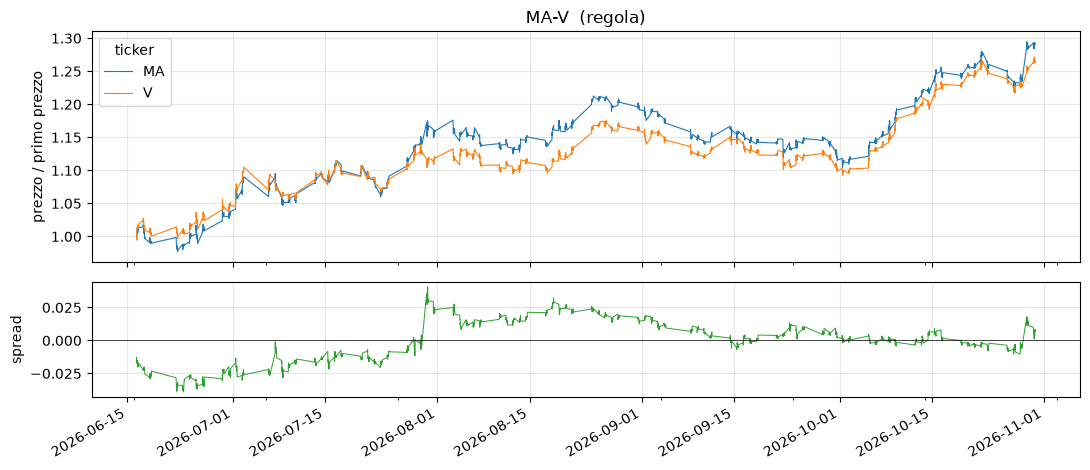

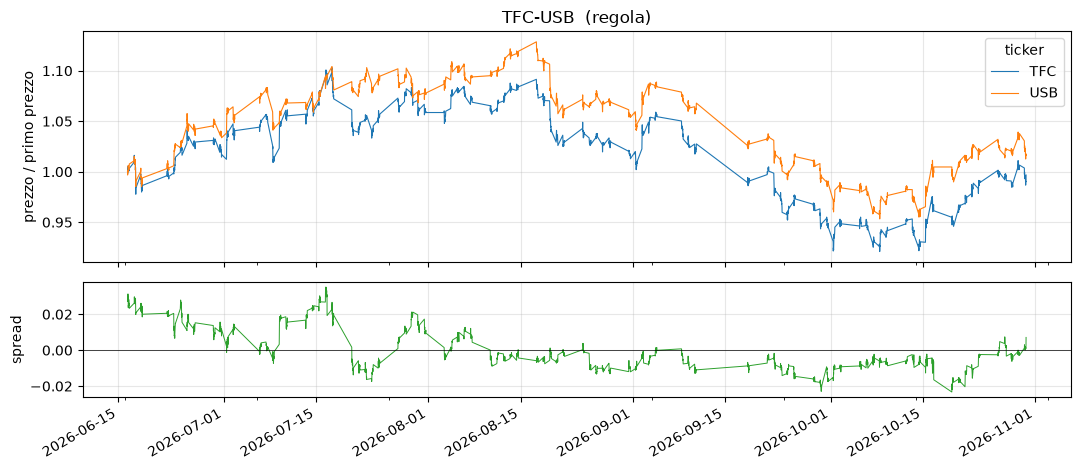

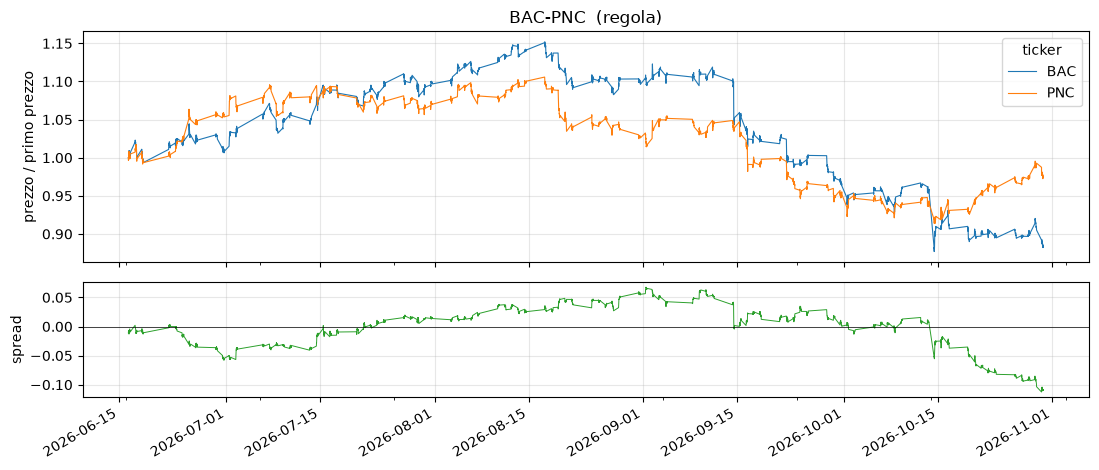

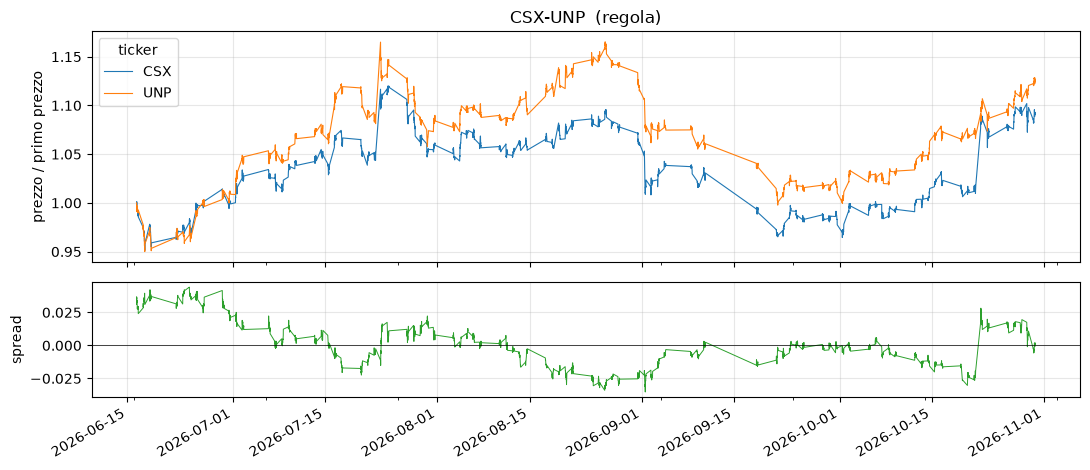

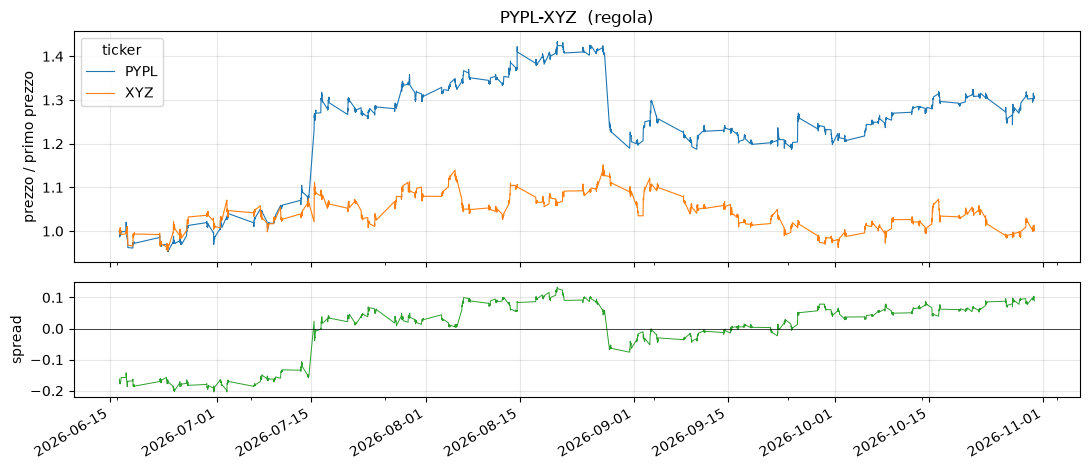

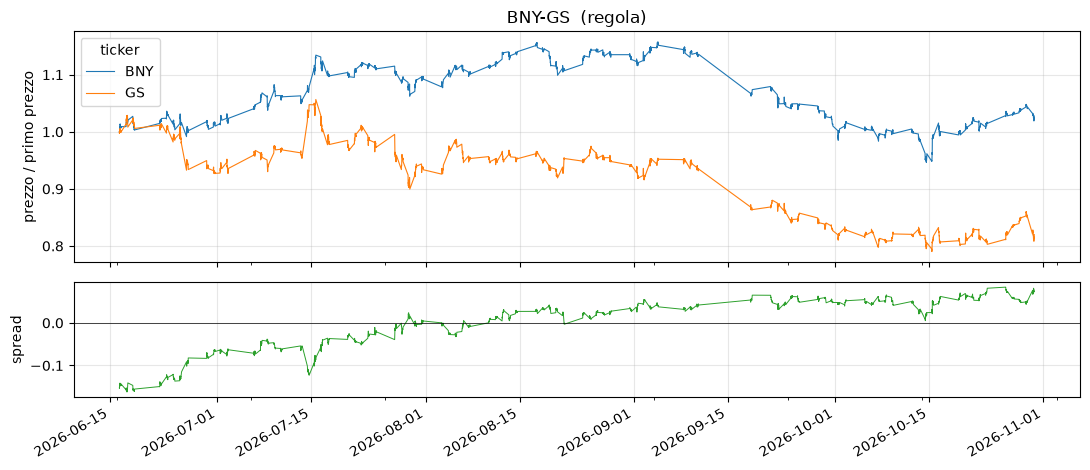

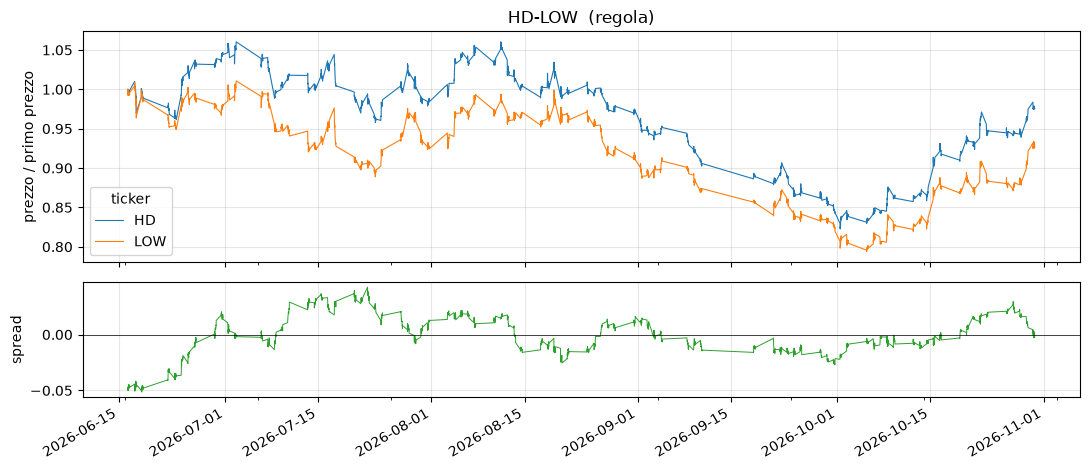

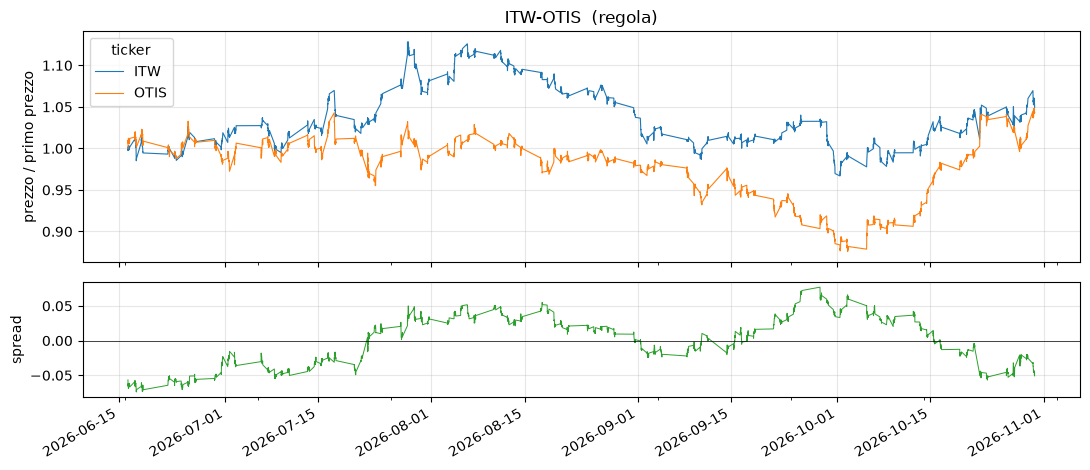

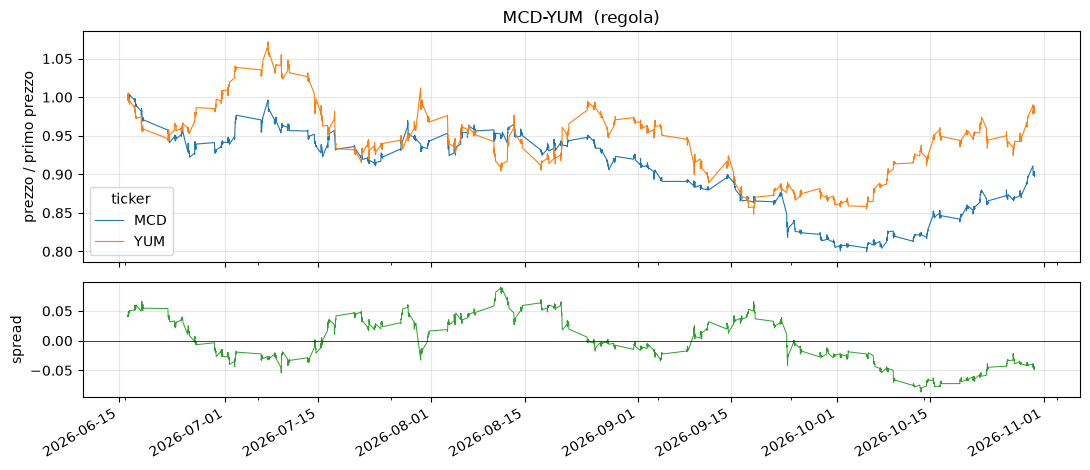

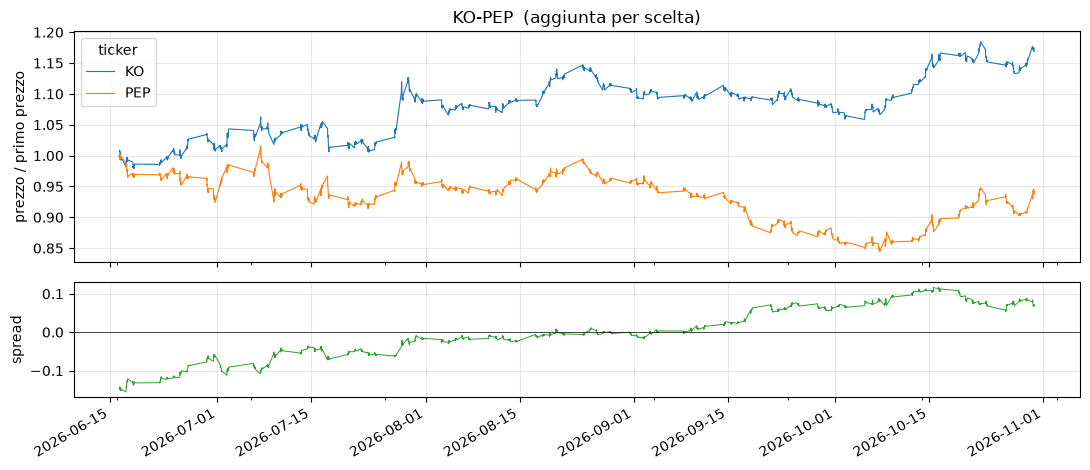

In [10]:
for p, long in clean.items():
    wide = resample_bars(long, 15).pivot(index="ts", columns="ticker", values="close")
    a, b = pairs.loc[pairs["pair"] == p, ["A", "B"]].iloc[0]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 4.8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    (wide / wide.iloc[0]).rename(columns=lambda c: c.split()[0]).plot(ax=ax1, lw=0.8)
    ax1.set_title(f"{p}  ({pairs.loc[pairs['pair'] == p, 'origine'].iloc[0]})"); ax1.set_ylabel("prezzo / primo prezzo"); ax1.grid(alpha=0.3)
    spread = np.log(wide[a] / wide[b]); (spread - spread.mean()).plot(ax=ax2, lw=0.7, color="C2")
    ax2.axhline(0, color="k", lw=0.5); ax2.set_ylabel("spread"); ax2.set_xlabel(""); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

## 9. Salvataggio e riepilogo

Si salva un file Parquet per ogni coppia e frequenza in `data/processed/pairs_intraday/` (cartella ignorata da git: chi nel gruppo ne ha bisogno rilancia il notebook), più la tabella di qualità in CSV. I file sono in formato lungo (un titolo per riga), come concordato per i passaggi successivi; la funzione `load_pair` qui sotto li restituisce già in forma larga (una colonna per titolo), comoda per calcolare lo spread.

In [11]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
con = duckdb.connect()
n_files = 0
for p, long in clean.items():
    for m in FREQUENCIES:
        df = resample_bars(long, m) if m != 1 else long
        con.register("t", df)
        con.execute(f"COPY t TO '{(OUT_DIR / f'{p}_{m}min.parquet').as_posix()}' (FORMAT PARQUET, COMPRESSION ZSTD)")
        con.unregister("t")
        n_files += 1
quality.to_csv(OUT_DIR / "quality_summary.csv")
print(n_files, "file salvati in", OUT_DIR.resolve())

40 file salvati in /Users/beatricerossi/Desktop/Project Models for Investements/DDM_Luiss_Project/data/processed/pairs_intraday


In [12]:
def load_pair(pair, minutes=1, field="close"):
    # Legge un file pulito e lo restituisce in forma larga: una riga per orario, una colonna per titolo.
    df = duckdb.sql(f"SELECT * FROM '{(OUT_DIR / f'{pair}_{minutes}min.parquet').as_posix()}'").df()
    return df.pivot(index="ts", columns="ticker", values=field)

load_pair("KO-PEP", 15).head()

ticker,KO UN Equity,PEP UW Equity
ts,,
2026-06-16 09:30:00,80.49,146.45
2026-06-16 09:45:00,80.31,146.02
2026-06-16 10:00:00,80.94,146.36
2026-06-16 10:15:00,81.20,147.20
2026-06-16 10:30:00,80.68,146.31


**Cosa è stato fatto e cosa resta aperto**
- I prezzi intraday dei 20 titoli sono controllati (split, giorni mancanti, giorni a orario ridotto), allineati per coppia e riempiti in avanti solo dentro la giornata, senza usare prezzi futuri.
- Per ogni coppia ci sono i file a 1, 5, 15 e 60 minuti e la tabella di qualità.
- **Limiti da dichiarare nel report:**
  1. il volume intraday è solo una parte del volume totale (in quota diversa per borsa): va usato come indicatore relativo, non assoluto;
  2. la quota di barre riempite è alta per i titoli poco scambiati (spread che cambia meno spesso di quanto sembri);
  3. giorni scartati per le coppie con dati mancanti: meno giorni a disposizione per addestramento e test;
  4. prezzi non aggiustati per dividendi: nei 96 giorni i dividendi sono pochi e piccoli, ma restano un'approssimazione.
- **Prossimo passo** (Passaggio 4): spread e segnale su questi file. La divisione tra addestramento e test (decisione 3) va ancora fissata.